# Bayesian workflow

A finished `fit()` is not the analysis. Construction records the design. It does not draw from the prior, and it does not check whether that prior can generate outcomes on the scale of the data. This page walks one {term}`Interrupted time series design` through the lifecycle CausalPy uses from version 1.0: configure the experiment, inspect the graph, check the prior, revise it if it fails, then fit and check the sampler and the posterior predictive. The steps follow {cite:t}`gelman2020workflow` and {cite:t}`gelman2026workflow`.

A prior is the model's claim before it conditions on the outcome. A posterior is that claim after. This page does not teach interrupted time series identification. The {doc}`interrupted time series how-to <../notebooks/interrupted-time-series-pymc>` does. The assumption that matters for the estimate below is that the pre-period relationship would have continued. Nothing on this page tests that assumption.

The same prior-check loop, on real series, is in the {doc}`COVID interrupted time series how-to <../notebooks/interrupted-time-series-covid>` and the {doc}`regression discontinuity how-to <../notebooks/regression-discontinuity-pymc>`.


## What a fit-first analysis hides

Before this lifecycle, constructing an experiment built the model and sampled immediately. A default prior on the wrong scale was already inside the posterior before anyone looked at it.

The series below is simulated weekly orders. Time is the integer week, `0` through `51`. Treatment starts at week 40. The formula used later is `y ~ 1 + t`. The pre-period mean sits near 8,000 orders, with a small trend and noise of a few hundred. The post period adds a planted level shift of about 1,200. That shift is stated here so the later posterior gap is a reality check against the simulation, not a discovery. Priors are judged only against the pre-period scale.

The plot is the outcome alone. No model has been built.


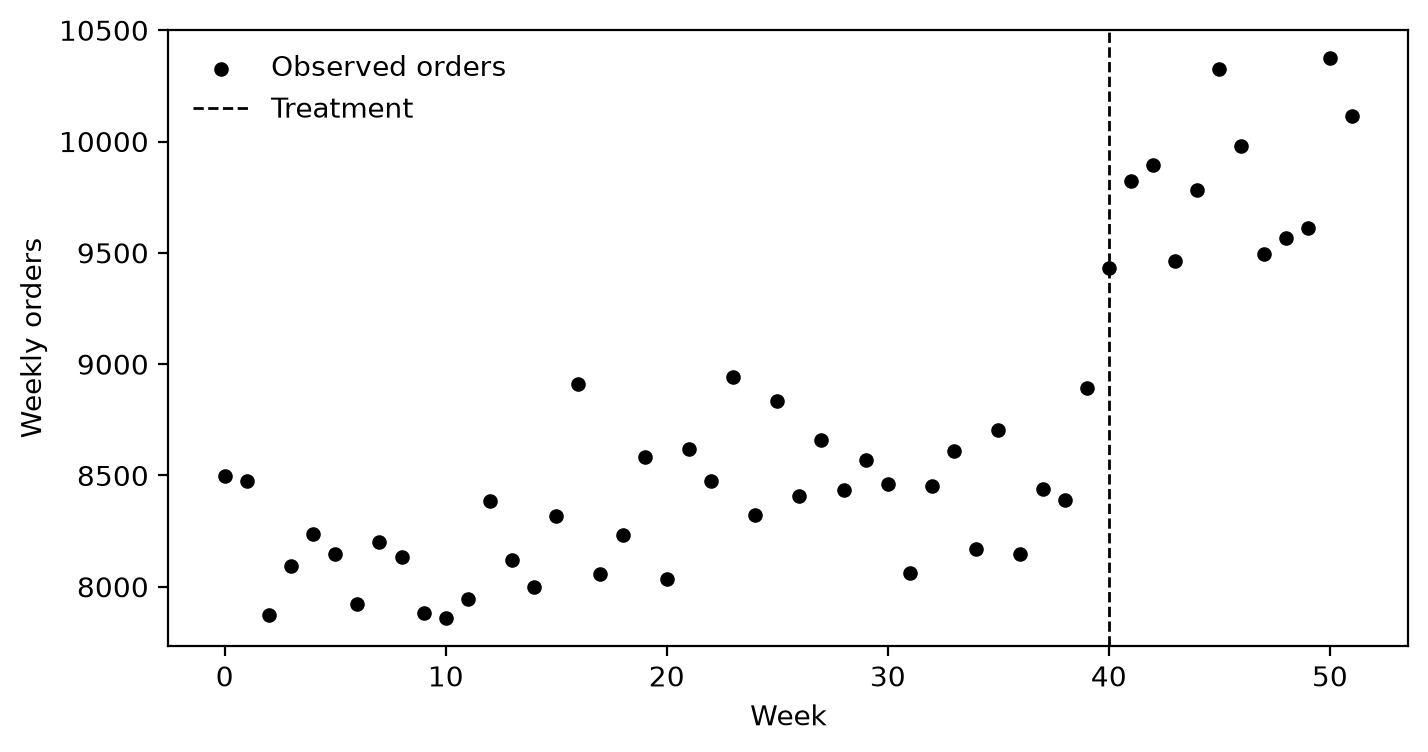

In [1]:
import arviz as az
import graphviz
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
from pymc_extras.prior import Prior

import causalpy as cp

%config InlineBackend.figure_format = "retina"

seed = sum(map(ord, "Bayesian workflow"))
rng = np.random.default_rng(seed)

treatment_time = 40
week = np.arange(52)
orders = 8_000 + 15 * week + rng.normal(0, 300, size=week.shape)
orders[week >= treatment_time] += 1_200
df = pd.DataFrame({"t": week, "y": orders})

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(df["t"], df["y"], color="k", s=18, label="Observed orders")
ax.axvline(treatment_time, color="k", linestyle="--", linewidth=1, label="Treatment")
ax.set(xlabel="Week", ylabel="Weekly orders")
ax.legend(frameon=False)
plt.show()

Black points are observed weekly orders. The dashed line is the treatment week. No model band is drawn.

The pre-period level is thousands of orders. A prior that cannot sit on that level fails the next check, whether or not `fit()` returns.


## Construction configures; it does not sample

`InterruptedTimeSeries(...)` stores the design. It does not draw. `build()` constructs the PyMC graph so the specification can be inspected before any sampling. The four flags below are the evidence for that split.


After construction: configured=True, built=False, fitted=False, prior=False
After build: configured=True, built=True, fitted=False, prior=False


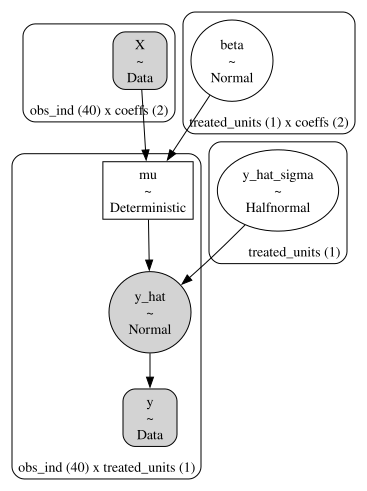

In [2]:
experiment = cp.InterruptedTimeSeries(
    df,
    treatment_time=treatment_time,
    formula="y ~ 1 + t",
)
print(
    f"After construction: configured={experiment.is_configured}, "
    f"built={experiment.is_built}, fitted={experiment.is_fitted}, "
    f"prior={experiment.has_prior_predictive}"
)

experiment.build()
print(
    f"After build: configured={experiment.is_configured}, "
    f"built={experiment.is_built}, fitted={experiment.is_fitted}, "
    f"prior={experiment.has_prior_predictive}"
)
pm.model_to_graphviz(experiment.model)

`is_configured` is true immediately. `is_built` becomes true only after `build()`. `is_fitted` and `has_prior_predictive` stay false. The graph shows the data nodes, the random variables `beta`, `y_hat`, and `y_hat_sigma`, and the deterministic node `mu`. There are no draws. The `obs_ind` plate has 40 rows because the likelihood is the pre-period only, the weeks before treatment at week 40. The post-period is not in that graph, and the post-period gap is not a node. Calling `fit()` here would skip the check the next section is for.


## The default prior is two claims, checked separately

`LinearRegression` uses one coefficient prior, `beta ~ Normal(0, 50)`, for every column, and an observation scale `y_hat_sigma ~ HalfNormal(1)`. Neither prior is scaled to the outcome. {cite:t}`gabry2019visualization` treat a prior predictive plot as the check of what the model allows before the outcome is conditioned on.

`plot(group="prior")` draws the prior {term}`counterfactual`, which is the mean path `mu`, not the observation noise. The noise claim needs a separate comparison.


Sampling: [beta, y_hat, y_hat_sigma]


Sampling: [y_hat]


Sampling: [y_hat]


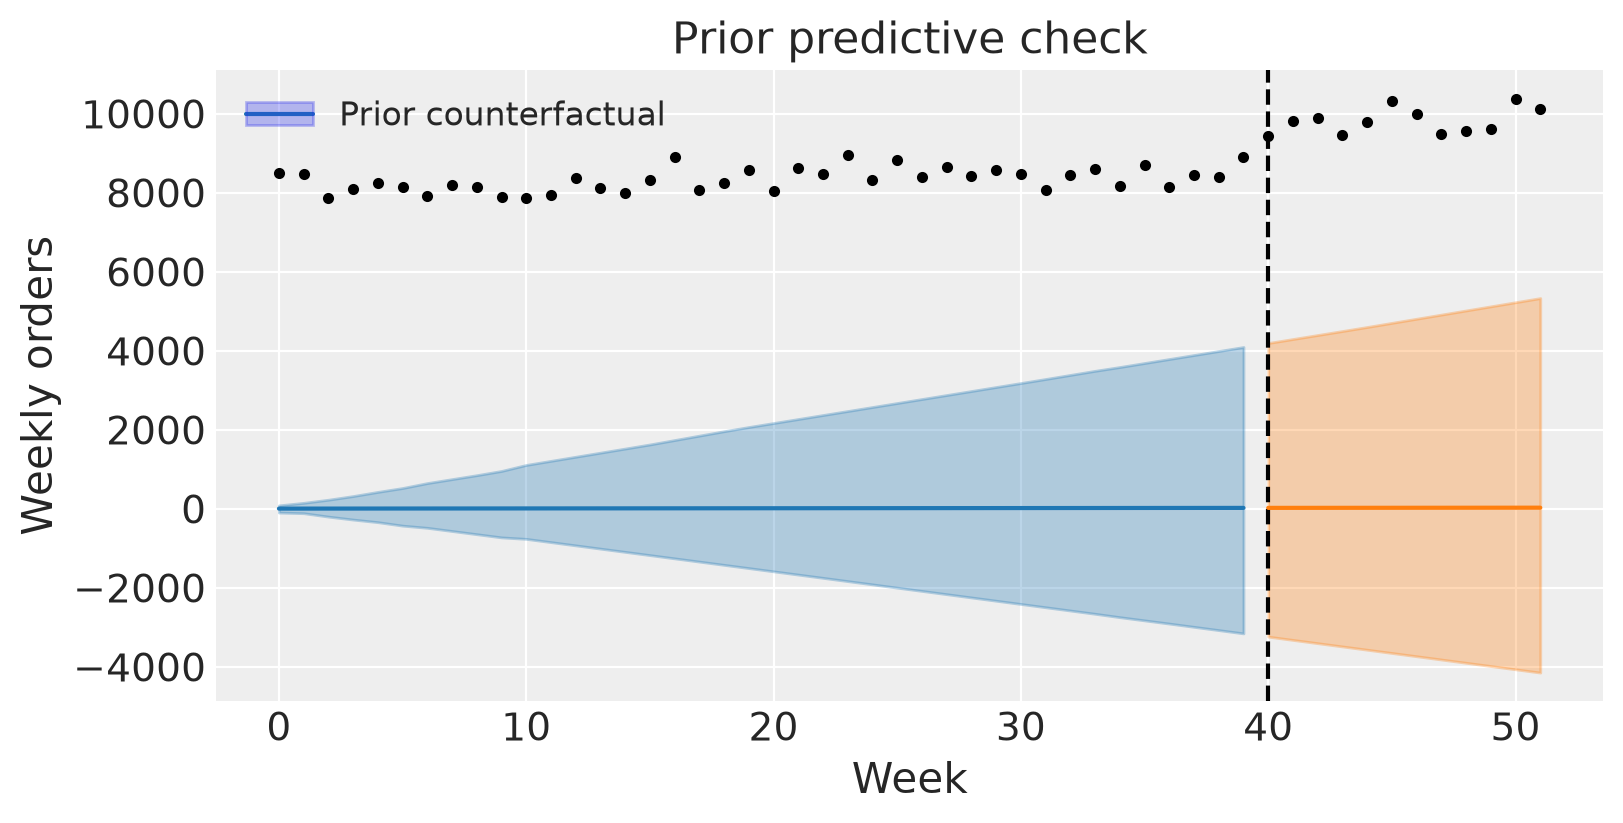

In [3]:
experiment.sample_prior_predictive(random_seed=seed)
fig, ax = experiment.plot(group="prior", figsize=(8, 4), show=False)
ax[0].set(xlabel="Week", ylabel="Weekly orders")
plt.show()

The legend entry is the prior counterfactual. The line inside each band is the expected path. Black points are the observations. The dashed line is the treatment week. The blue band is the pre-period path and the orange band is the post-period path. Post-period points are orientation, not a target for the prior.

The expected path sits at zero because `beta` is centered at 0. The observations sit near 8,000. The ribbon widens with time because the slope prior is `Normal(0, 50)`, not because of `HalfNormal(1)`. This figure is not evidence about the noise prior.


In [4]:
pre = df.loc[df["t"] < treatment_time]
slope, intercept = np.polyfit(pre["t"], pre["y"], 1)
residual_sd = float((pre["y"] - (intercept + slope * pre["t"])).std(ddof=1))
sigma = experiment.idata["prior"]["y_hat_sigma"]
print(f"Pre-period residual scale: {residual_sd:.0f}")
print(f"Prior y_hat_sigma median: {float(sigma.median()):.2f}")
print(f"Prior y_hat_sigma 94% quantile: {float(sigma.quantile(0.94)):.2f}")

Pre-period residual scale: 266
Prior y_hat_sigma median: 0.68
Prior y_hat_sigma 94% quantile: 1.95


The prior draws of `y_hat_sigma` stay near 1. The pre-period residual scale printed above is a few hundred. That comparison still fails if `beta` is revised and `HalfNormal(1)` is left in place. The path plot will not show it.


In [5]:
print(experiment.effect_summary(group="prior").text)

Prior predictive check (not a causal estimate): During the Post-period (40 to 51), the response variable had an average value of approx. 9822.06. By contrast, in the absence of an intervention, we would have expected an average response of 23.40. The 95% interval of this counterfactual prediction is [-4081.57, 4784.47]. Subtracting this prediction from the observed response yields an estimate of the causal effect the intervention had on the response variable. This effect is 9798.66 with a 95% interval of [5037.60, 13903.63].

Summing up the individual data points during the Post-period, the response variable had an overall value of 117864.74. By contrast, had the intervention not taken place, we would have expected a sum of 280.81. The 95% interval of this prediction is [-48978.81, 57413.58]. The cumulative effect is 117583.93 with a 95% HDI [60451.16, 166843.55].

The prior probability of an increase is 1.000. For the cumulative effect, The prior probability of an increase is 1.000. R

The first sentence is the instruction: `Prior predictive check (not a causal estimate)`. The rest of the text is the same template the posterior summary uses, including the words "causal effect" and the continuation assumption. Those sentences are not a finding from these draws. The prior probability of an increase is 1 because the prior counterfactual sits near 0 while the observations do not. That is the scale failure again, not a discovered effect. The summary does not report `y_hat_sigma`.


## Revise the prior before any posterior

`InterruptedTimeSeries` has no `priors=` argument. The documented revision is assignment of a fresh model, which clears the prior state. Do not call `fit()` on the rejected default.

The coefficient prior has to be one vector in `experiment.labels` order. For `y ~ 1 + t` that order is `Intercept`, then `t`. A scalar `beta` prior cannot say "intercept near 8,000, slope near 0". A scalar mean of 8,000 would also center the slope at 8,000 orders per week, so the prior mean path would climb by thousands of orders a week and still miss the pre-period.

The claims below use only the pre-period scale: intercept mean 8,000 with width 1,500, slope mean 0 with width 40 orders per week, and observation noise on a scale of a few hundred.


In [6]:
prior_specs = {
    "Intercept": (8_000, 1_500),
    "t": (0, 40),
}
beta_mu = [prior_specs[name][0] for name in experiment.labels]
beta_sigma = [prior_specs[name][1] for name in experiment.labels]
print("labels", list(experiment.labels))
print("beta mu", beta_mu)
print("beta sigma", beta_sigma)

experiment.model = cp.pymc_models.LinearRegression(
    priors={
        "beta": Prior(
            "Normal",
            mu=beta_mu,
            sigma=beta_sigma,
            dims=["treated_units", "coeffs"],
        ),
        "y_hat": Prior(
            "Normal",
            sigma=Prior("HalfNormal", sigma=400, dims=["treated_units"]),
            dims=["obs_ind", "treated_units"],
        ),
    }
)
print(f"Prior state cleared: {not experiment.has_prior_predictive}")
experiment.sample_prior_predictive(random_seed=seed)
print(f"Prior redrawn: {experiment.has_prior_predictive}")

Sampling: [beta, y_hat, y_hat_sigma]


Sampling: [y_hat]


Sampling: [y_hat]


labels ['Intercept', 't']
beta mu [8000, 0]
beta sigma [1500, 40]
Prior state cleared: True
Prior redrawn: True


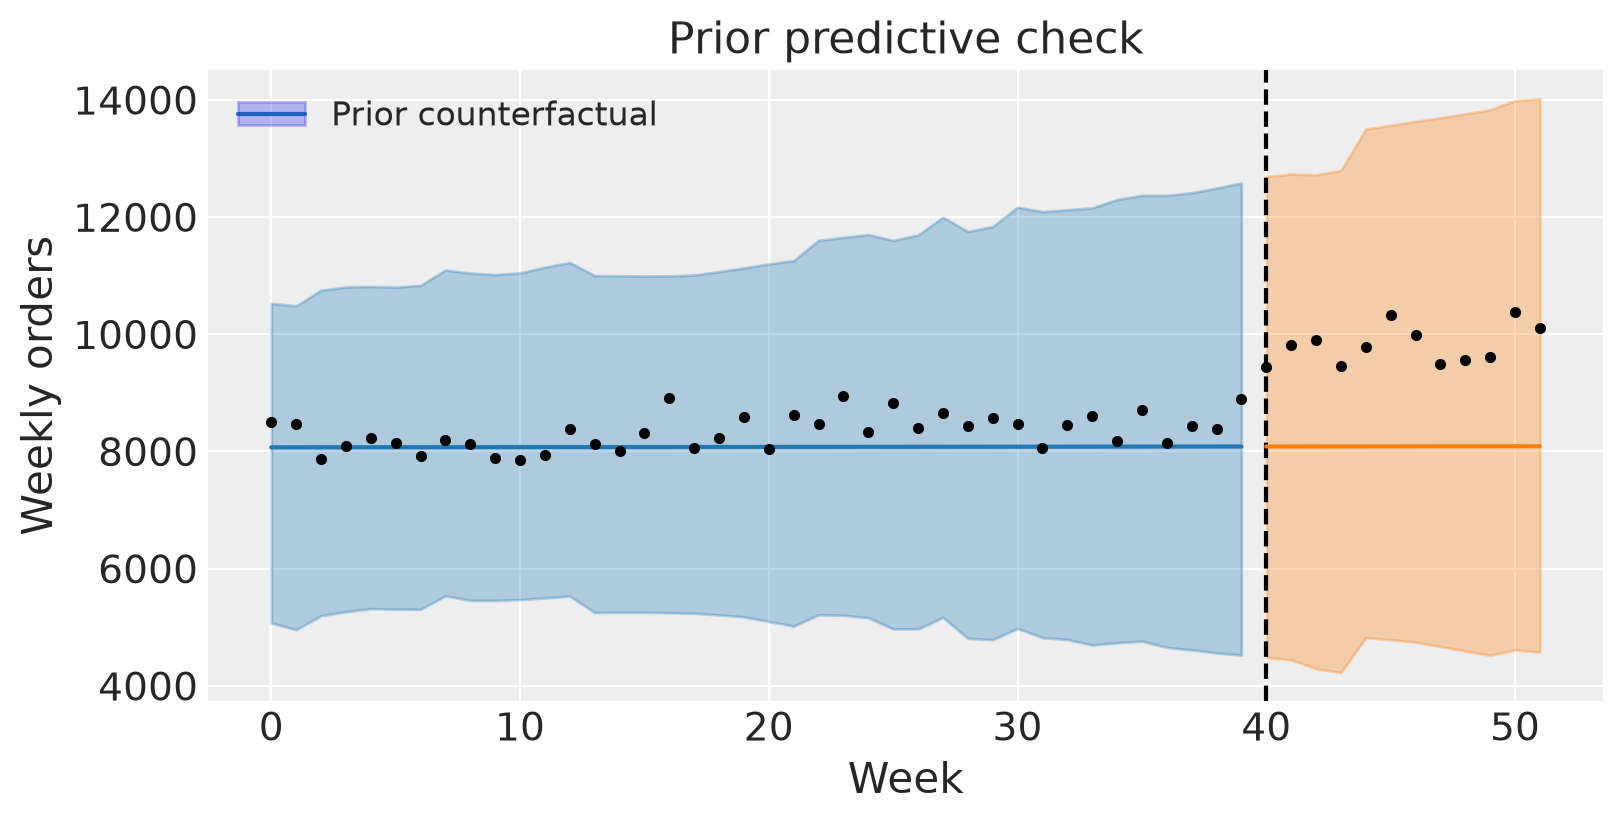

In [7]:
fig, ax = experiment.plot(group="prior", figsize=(8, 4), show=False)
ax[0].set(xlabel="Week", ylabel="Weekly orders")
plt.show()

Same marks as the default prior plot. The line is the prior mean path under the vector `beta` prior. The band is the uncertainty of that path.

The pre-period level is now inside that band. This plot is the location re-check only. It does not show whether the noise prior was revised.


In [8]:
sigma = experiment.idata["prior"]["y_hat_sigma"]
print(f"Pre-period residual scale: {residual_sd:.0f}")
print(f"Revised y_hat_sigma median: {float(sigma.median()):.0f}")
print(f"Revised y_hat_sigma 94% quantile: {float(sigma.quantile(0.94)):.0f}")

Pre-period residual scale: 266
Revised y_hat_sigma median: 272
Revised y_hat_sigma 94% quantile: 778


The revised `y_hat_sigma` median is now near the pre-period residual scale, not near 1. The upper quantile is wider than that scale, which is what a broad noise prior should do. Both failed claims have been replaced. The printed comparison is a scale check, not a causal result.

This revision is not a sensitivity analysis. The first prior failed the prior check, so it is not an alternative worth comparing after fitting.


## Fit, then check the sampler

A plausible prior does not mean the sampler found the posterior. `fit()` samples the posterior of `beta` and `y_hat_sigma` with NUTS. The `Sampling: [y_hat]` lines after that block are not another prior phase. They forward-sample `y_hat` from the posterior just drawn: the posterior predictive, the pre-period path, the post-period path, and the pre-period score. `mu` is computed from those same posterior draws. The log does not list it, because it is not resampled as its own random variable. None of those lines call `sample_prior_predictive()`, and none of them replace the prior draws already stored. That skip is not a general fact about `fit()`. A fit-first call still samples the posterior and then fills prior state that was never used to reject the default. The lifecycle diagram below shows that branch. The revised prior plot above does not.

The sampling settings are short on purpose: two chains, 200 tuning steps, 200 draws. Published diagnostics should come from a longer run. The printed summary, including any sampler warning, is the check.


In [9]:
experiment.fit(
    chains=2,
    tune=200,
    draws=200,
    cores=1,
    random_seed=seed,
    progressbar=False,
)
az.summary(experiment.idata, var_names=["beta", "y_hat_sigma"])

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (2 chains in 1 job)


NUTS: [beta, y_hat_sigma]


Sampling 2 chains for 200 tune and 200 draw iterations (400 + 400 draws total) took 0 seconds.


We recommend running at least 4 chains for robust computation of convergence diagnostics


The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


Sampling: [y_hat]


Sampling: [y_hat]


Sampling: [y_hat]


Sampling: [y_hat]


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
"beta[unit_0, Intercept]",8.11e+03,80,8000,8200,223,199,1.00,5.3,3.5
"beta[unit_0, t]",11.6,3.3,6.1,17,238,236,1.00,0.22,0.15
y_hat_sigma[unit_0],275,32,220,330,186,168,1.01,2.4,1.9


In [10]:
n_divergences = int(experiment.idata["sample_stats"]["diverging"].sum())
print(f"Divergences: {n_divergences}")

Divergences: 0


The summary rows are the pre-period intercept, the pre-period slope, and the observation-noise scale. They are not the interruption. The causal estimate, if the pre-period relationship would have continued, is the post-period gap in the next section.

The warning's per-chain effective sample size is the summary's effective sample size divided by the number of chains. On this short run that per-chain number is too small, and two chains are fewer than the four the warning asks for, so the printed R-hat and effective sample size are not yet a reliable check that the chains agree. R-hat near 1, a large effective sample size, and no divergences are what a longer run uses to say the chains agree {cite:t}`vehtari2021rank`. They do not mean the interruption is causal, and they do not identify that gap. The warning is a sampler-length problem. It is not a finding about the orders.


## Posterior predictive check

The posterior predictive check asks whether the fitted model reproduces the pre-period pattern it was asked to learn {cite:t}`gabry2019visualization`. `plot(group="posterior")` returns three panels. There is no separate pre-period panel. The check is the region before the treatment line on the predictions panel and on the impact panel. The estimate is the post-period gap on those same two panels. The third panel is the cumulative sum of that gap, not a second estimate. The $R^2$ written into the first title is the API's pre-period score. It is not the check.


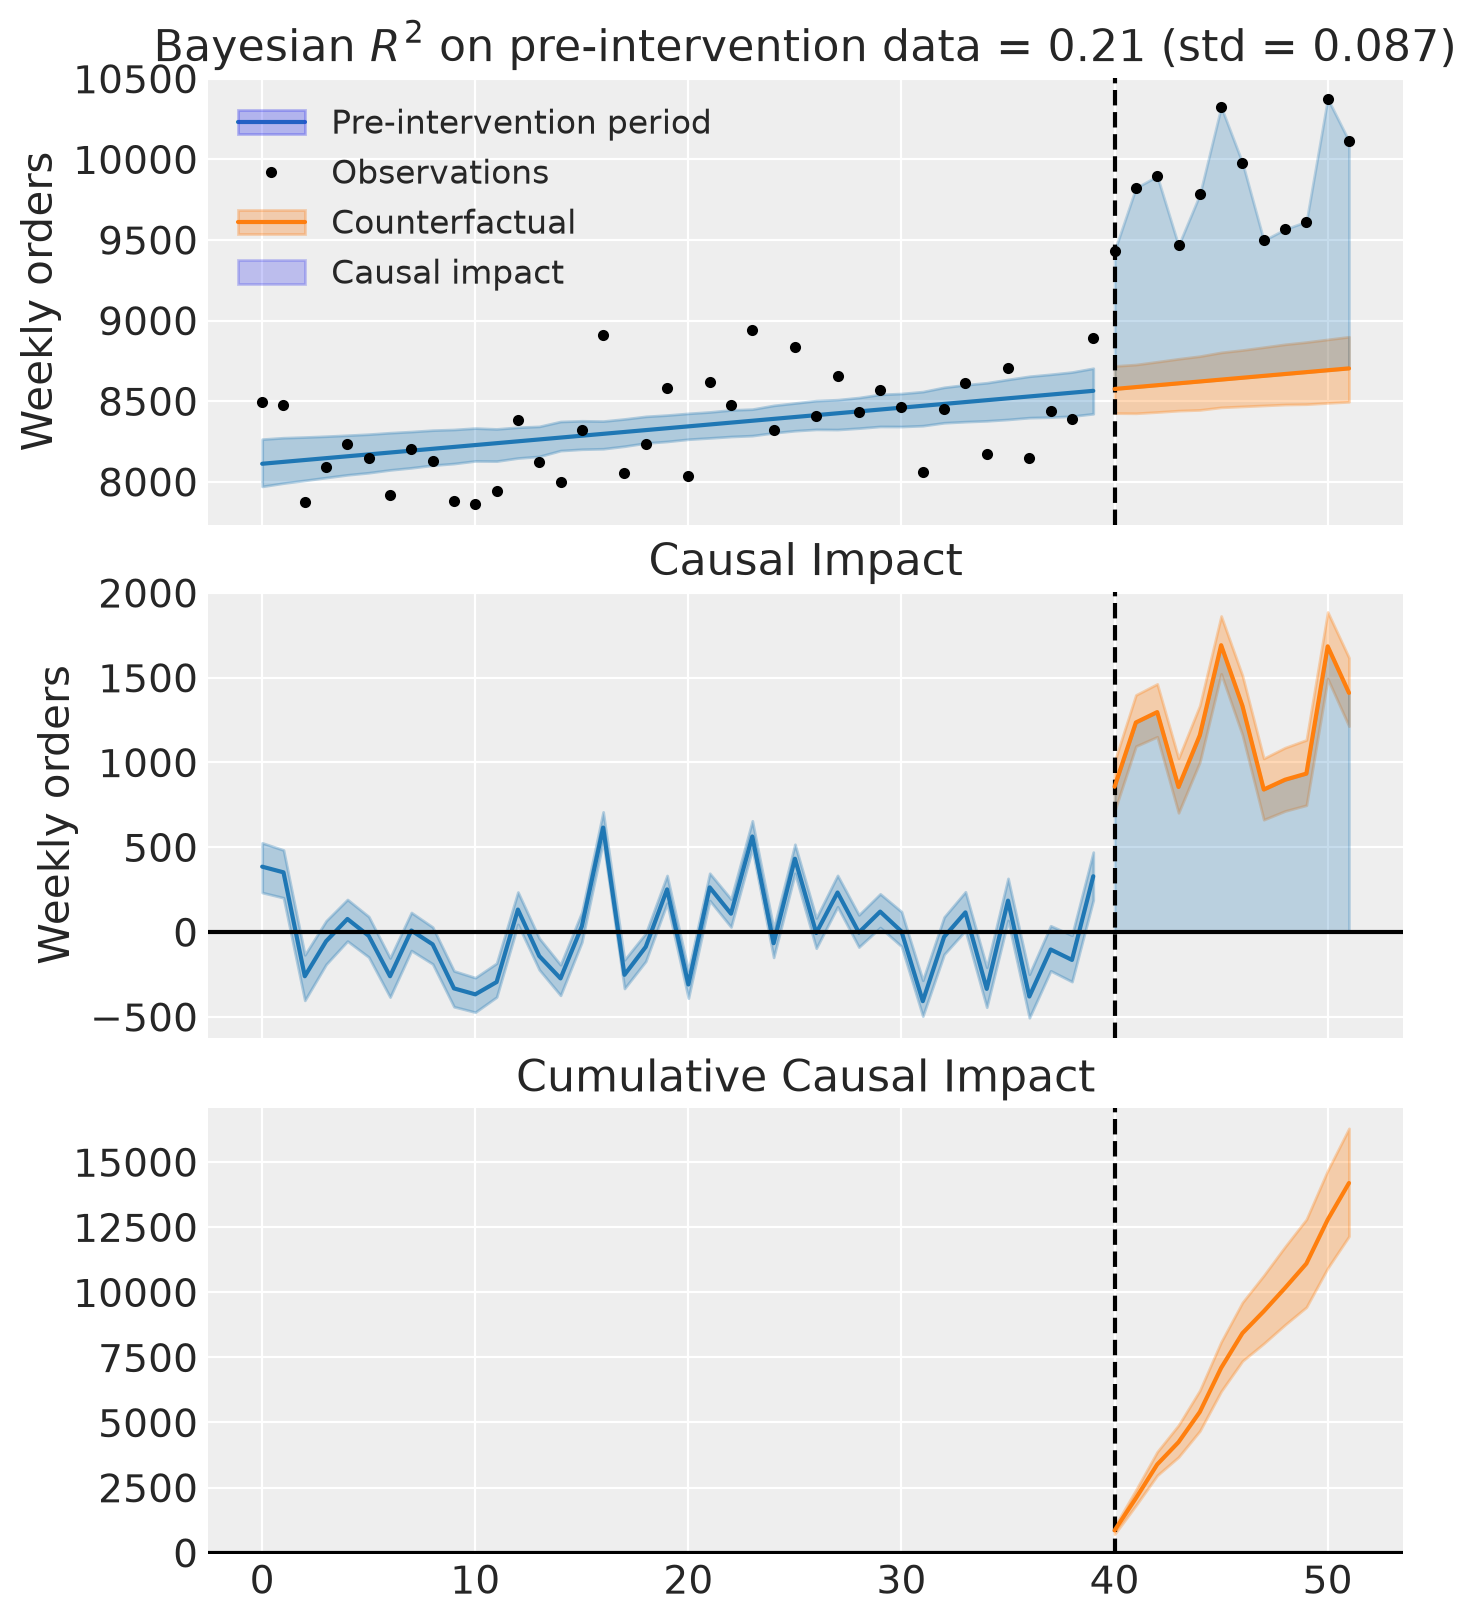

In [11]:
fig, axes = experiment.plot(group="posterior", show=False)
axes[0].set(ylabel="Weekly orders")
axes[1].set(ylabel="Weekly orders")
plt.show()

The legend names the marks: pre-intervention period, observations, counterfactual, and {term}`causal impact`. The vertical line is the treatment week.

Before that line, the blue band is uncertainty in the fitted mean, not a prediction interval for each week. Points scatter around it. That scatter is the observation noise of a few hundred, not a failed check. The check is the middle panel before the line: the gap wanders around zero rather than showing a systematic miss. After the line, the gap between the observations and the counterfactual is the estimate, under the assumption that the pre-period relationship would have continued. The legend calls that gap a causal impact. The name is the API's. The assumption is still required. The bottom panel adds that gap up. It is not a second estimate. The $R^2$ in the top title is the API's pre-period score, not the check and not the estimate.

The simulation planted a level shift of about 1,200. Compare the post-period gap with that planted shift as a reality check, not as identification. The {doc}`interrupted time series how-to <../notebooks/interrupted-time-series-pymc>` states the continuation assumption this estimate needs.


## Prior sensitivity is the next question, not this fit

The default prior failed the prior check. Fitting it and comparing its posterior with the revised posterior would not be a sensitivity analysis. The question that remains, after a prior has passed, is whether another prior that also passed would move the effect.

`PriorSensitivity` is a check you add. It re-fits declared alternative models and compares effect summaries. It is not what `SensitivityAnalysis.default_for` registers for interrupted time series. That default suite is a placebo-in-time check. It asks whether the estimated effect is distinctive against a placebo null, which is a different question, and it is not run here. How to add a check is on the {doc}`sensitivity checks page <../notebooks/sensitivity_checks>`.


## When a check fails, and where comparison fits

Each row is a different failure. The next action is not always "fit again".

| What failed | What it means | Next action |
| --- | --- | --- |
| Prior counterfactual misses the pre-period level | The coefficient prior, not the data, is the problem | Revise the `beta` vector and re-check the path. Do not fit yet |
| Prior `y_hat_sigma` stays near 1 while pre-period residuals are a few hundred | The noise prior is still on the wrong scale | Revise the `y_hat` prior and re-check `y_hat_sigma`. The path plot will not show this |
| R-hat far from 1, tiny effective sample size, or divergences | The sampler did not deliver the posterior | Sampling or parameterization problem, not a causal finding |
| Pre-period region of the posterior predictions or impact panel misses the observed pattern | The formula or likelihood is wrong | Change the model. Do not tighten the prior to hide it. The cumulative panel and the $R^2$ title are not this check |
| A second prior that also passed the prior check moves the effect | The conclusion depends on the prior | Add `PriorSensitivity`. Do not rely on the interrupted time series default suite |
| Two specifications both passed the checks | Comparison can ask which predicts better | Leave-one-out or ELPD, after those checks, not instead of them |

A failed prior is revised before fitting, not carried into a posterior comparison {cite:t}`schad2021toward`.

Model comparison sits after both specifications have passed the prior check and the sampler check. It asks which model predicts held-out observations better, not whether either specification identifies the effect {cite:t}`vehtari2017practical`. CausalPy has no experiment method for that comparison, so this page does not compute one. A hand-rolled comparison here would be a second analysis, not the next step of this fit.

{cite:t}`mcelreath2020rethinking` and {cite:t}`martin2021bayesian` are longer courses for a reader who wants the probability background this page assumed.


## The lifecycle, now that each step has a reason

The diagram answers two questions: what to call, in order, and what a fit-first call still does. The left branch is the example on this page. The right branch is the call the opening asked about.


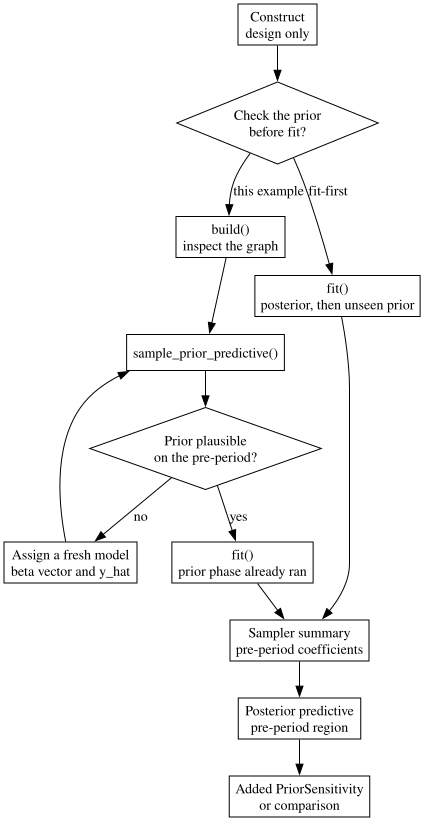

In [12]:
lifecycle = graphviz.Digraph(graph_attr={"rankdir": "TB"})
lifecycle.attr("node", shape="box")
lifecycle.node("construct", "Construct\ndesign only")
lifecycle.node("choice", "Check the prior\nbefore fit?", shape="diamond")
lifecycle.node("build", "build()\ninspect the graph")
lifecycle.node("prior", "sample_prior_predictive()")
lifecycle.node("revise", "Prior plausible\non the pre-period?", shape="diamond")
lifecycle.node("assign", "Assign a fresh model\nbeta vector and y_hat")
lifecycle.node("fit", "fit()\nprior phase already ran")
lifecycle.node("fitfirst", "fit()\nposterior, then unseen prior")
lifecycle.node("diag", "Sampler summary\npre-period coefficients")
lifecycle.node("post", "Posterior predictive\npre-period region")
lifecycle.node("later", "Added PriorSensitivity\nor comparison")
lifecycle.edge("construct", "choice")
lifecycle.edge("choice", "build", label="this example")
lifecycle.edge("choice", "fitfirst", label="fit-first")
lifecycle.edge("build", "prior")
lifecycle.edge("prior", "revise")
lifecycle.edge("revise", "assign", label="no")
lifecycle.edge("assign", "prior")
lifecycle.edge("revise", "fit", label="yes")
lifecycle.edge("fit", "diag")
lifecycle.edge("fitfirst", "diag")
lifecycle.edge("diag", "post")
lifecycle.edge("post", "later")
lifecycle

Prior checking before `fit()` is the recommended order, not the only order the API allows. On the fit-first branch the posterior is still sampled, and prior state is filled afterwards, unseen. That filled prior was not used to reject a default. The `Sampling: [y_hat]` lines in the fit output above are the left branch: posterior forward sampling, not that unseen prior fill. The example ends here.

:::{bibliography}
:filter: docname in docnames
:::
